# SLU12 - Feature Engineering: Exercises notebook

In this exercise notebook, we will be using a dataset from Zomato, adapted from [here](https://github.com/MehtaShruti/Zomato-Restaurants-Recommendations).

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import KBinsDiscretizer, Binarizer, MinMaxScaler, StandardScaler, RobustScaler
import category_encoders as ce
import json
import hashlib

plt.rcParams["figure.figsize"] = [5.6, 4.2]

In [24]:
data = pd.read_csv('data/zomato.csv').convert_dtypes()
data.head()

,Restaurant Name,City,Cuisines,Average Cost for two,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating color,Rating text,Votes
0,Jahanpanah,Agra,"North Indian, Mughlai",850,No,No,3,3.9,Yellow,Good,140
1,Rangrezz Restaurant,Agra,"North Indian, Mughlai",700,No,No,2,3.5,Yellow,Good,71
2,Time2Eat - Mama Chicken,Agra,North Indian,500,No,No,2,3.6,Yellow,Good,94
3,Chokho Jeeman Marwari Jain Bhojanalya,Agra,Rajasthani,400,No,No,2,4.0,Green,Very Good,87
4,Pinch Of Spice,Agra,"North Indian, Chinese, Mughlai",1000,No,No,3,4.2,Green,Very Good,177


These are the dataset's fields:

- **Restaurant Name** - the name of the restaurant
- **City** - the name of the city where the restaurant is located
- **Cuisines** - the type of cuisine served in the restaurant
- **Average Cost for two** - self explanatory (as when scraped)
- **Has Table booking** - Yes or No
- **Has Online delivery** - Yes or No
- **Price Range** - prices range from 1 to 4
- **Aggregate rating** - the overall user rating of from the app (as when scraped) from 0 to 5
- **Rating color** - a rating according to color: White, Red, Orange, Yellow, Green, and Dark Green
- **Rating text** - a rating in text values: Not Rated, Poor, Average, Good, Very Good, and Excellent
- **Votes** - the number of user reviews for the restaurant (as when scraped).

The first thing we want to do is to check the dtypes of our features.

In [25]:
data.dtypes

Restaurant Name          string
City                     string
Cuisines                 string
Average Cost for two      Int64
Has Table booking        string
Has Online delivery      string
Price range               Int64
Aggregate rating        Float64
Rating color             string
Rating text              string
Votes                     Int64
dtype: object

### Exercise 1: Convert fields into category dtype

The fields `Cuisines` and `Rating text` are of dtype `string` but can be converted into dtype `category` as explained in the Learning Notebook. Moreover:
* `Cuisines` is a *nominal* categorical field, that is, without any meaningful order;
* `Rating text` is an *ordinal* categorical field, as its values have a natural order.

Implement a function that converts both fields into dtype `category`. For the field `Rating text`, assign a natural order (the order shown in the field description above) to its categories. 

In [26]:
def convert_categorical_features(X, nominal_feat='Cuisines', ordinal_feat='Rating text'):
    """
    Converts features to categoricals.

    Args:
        X (pd.Dataframe): dataframe containing the features
        nominal_feat (string): name of the column to be converted to a nominal categorical
        ordinal_feat (string): name of the column to be converted to an ordinal categorical
    Returns:
        X_s (pd.Dataframe): dataframe with converted features
    """

    X_s = X.copy()

    X_s[nominal_feat] = X_s[nominal_feat].astype('category')

    rating_order = ['Not rated', 'Poor', 'Average', 'Good', 'Very Good', 'Excellent']
    X_s[ordinal_feat] = pd.Categorical(
        X_s[ordinal_feat],
        categories=rating_order,
        ordered=True
    )

    return X_s

In [27]:
data = pd.read_csv('data/zomato.csv').convert_dtypes()
X_cat_conv = convert_categorical_features(data).sort_index()
assert isinstance(X_cat_conv,pd.DataFrame), 'The output should be a pandas dataframe.'
assert X_cat_conv.shape == data.shape, 'The shape of the resulting dataframe is not correct.'
assert hashlib.sha256(json.dumps(''.join(X_cat_conv['Cuisines'].cat.categories)).encode()).hexdigest() == \
'875db838974d741147364c1ae990394a17f116f71a6416d7f18a963bb9c2f32e', 'The categories in the Cuisines column are not correct.'
assert hashlib.sha256(json.dumps(''.join(X_cat_conv['Cuisines'])).encode()).hexdigest() == \
'91289e66b5cdfe2d43b27292b3aab447277b6b580347eb3c02f8fc5dc631beed', 'The column Cuisines is not converted correctly.'
assert hashlib.sha256(json.dumps(''.join(X_cat_conv['Rating text'].cat.categories)).encode()).hexdigest() == \
'07b1f6b0b1036161f4a66541aaf088334abc844d809c1e8dbe12dd823a5c8ef2', 'The categories in the `Rating text` column are not correct.'
assert hashlib.sha256(json.dumps(''.join(X_cat_conv['Rating text'])).encode()).hexdigest() == \
'4d5368da2c1a897e85fce3a6cf80c3d0feefefee8f6da916aecd0f9e2f7dca6b', 'The column Rating text is not converted correctly.'

### Exercise 2: Encode a binary field
Implement a function that encodes the column `Has Table booking` to `1`, when a restaurant has a table booking; encode the column to `0`, when it doesn't. Use the `map` method for the encoding.

In [28]:
def encode_binary_field(f):
    """
    Binarizes the provides series.

    Args:
        f (pd.Series): series to be binarized
    Returns:
        f_e (pd.Series): binarized series
    """

    f_e = f.copy()
    
    f_e = f_e.map({'Yes': 1, 'No': 0})

    return f_e

In [29]:
data = pd.read_csv('data/zomato.csv').convert_dtypes()
f_encoded = encode_binary_field(data['Has Table booking']).sort_index()
assert isinstance(f_encoded,pd.Series), 'The output should be a pandas series.'
assert f_encoded.shape == data['Has Table booking'].shape, 'The shape of the encoded series is not correct.'
assert f_encoded.dtype==int, 'The data type of the converted column is not correct.'
assert hashlib.sha256(json.dumps(''.join(f_encoded.astype(str))).encode()).hexdigest() == \
'f0d67268c35fdc5ae2780045cb6548bca5b45a4334291d57ad3238ed924f7bc6', 'The values in the converted column are not correct.'

### Exercise 3: Discretize the `Votes` field

The field `Votes` is an integer variable with a distribution which is, not surprisingly, very skewed to the left (remember *skewness* from SLU04?).

The field 'Votes' ranges from 0 to 10934


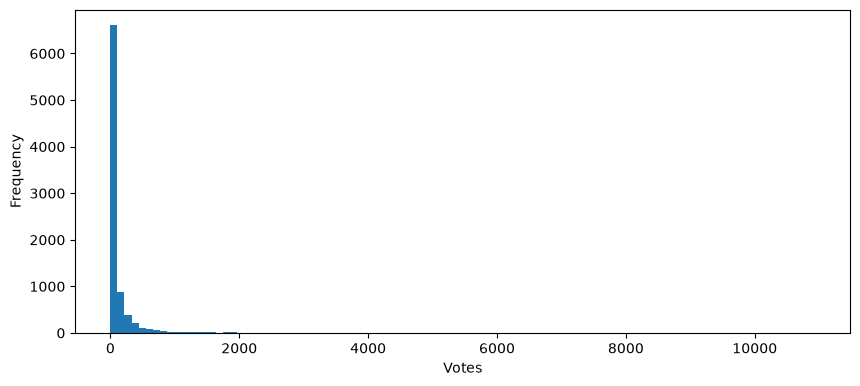

In [30]:
data['Votes'].plot.hist(bins=100, figsize=(10,4.2));
plt.xlabel('Votes');
print("The field 'Votes' ranges from", data['Votes'].min(), "to", data['Votes'].max())

We will deal with the skewness in a bit. Let's first discretize this field in two ways:
* create a new field called `discrete_votes` which is the discretization of the `Votes` field, such that the range is between 0 and 49 and the bins are of equal size;
* create a new field called `binary_votes` which is the binarization of the `Votes` field, such that amounts up to `100` become `0` and amounts greater than `100` become 1.

Implement it in the function below using the `sklearn` transformers.

**Note:** When using `KBinsDiscretizer`, convert the input DataFrame columns to independent NumPy arrays using `.to_numpy(dtype=float, copy=True)` to avoid compatibility issues with Pandas nullable data types.

In [31]:
def discretize_votes(X):
    """
    Discretized the Votes column from the provided dataframe in two ways,
    creating two new columns 'discrete_votes' and 'binary_votes'.
    discrete_votes: discretization to 0-49 with equally sized bins
    binary_votes: binarization with a cut off at 100

    Args:
        X (pd.DataFrame): dataframe with the data to be discretized
    Returns:
        X_a (pd.DataFrame): dataframe with the new discretized columns
    """

    X_a = X.copy()

    discretizer = KBinsDiscretizer(n_bins=50, encode='ordinal', strategy='uniform', )
    X_a["discrete_votes"] = discretizer.fit_transform(X_a[["Votes"]].to_numpy(dtype=float, copy=True))
    binarizer = Binarizer(threshold=100)
    X_a["binary_votes"] = binarizer.fit_transform(X_a[["Votes"]].to_numpy(dtype=float, copy=True))

    return X_a

In [32]:
data = pd.read_csv('data/zomato.csv').convert_dtypes()
X_votes = discretize_votes(data)
assert isinstance(X_votes,pd.DataFrame), 'The output should be a pandas dataframe.'
assert X_votes.shape == (data.shape[0],data.shape[1]+2), 'The shape of the resulting dataframe is not correct.'
assert 'discrete_votes' in X_votes.columns, 'The discrete_votes column is missing.'
assert 'binary_votes' in X_votes.columns, 'The binary_votes column is missing.'
assert hashlib.sha256(json.dumps(''.join(X_votes['binary_votes'].astype(str))).encode()).hexdigest() == \
'3968711c9ae79545ed0b26f8b95c590a0f9670f3bdf341b1f6ff654bf011095e', 'The binary_votes column is not encoded correctly.'
assert hashlib.sha256(json.dumps(''.join(X_votes['discrete_votes'].astype(str))).encode()).hexdigest() == \
'75d872b9a4c7df92e760c8e1b02b7451c1797cfac1b1546ae9586699d08903a9', 'The discrete_votes column is not encoded correctly.'

Check the distribution of the two new fields you just calculated:

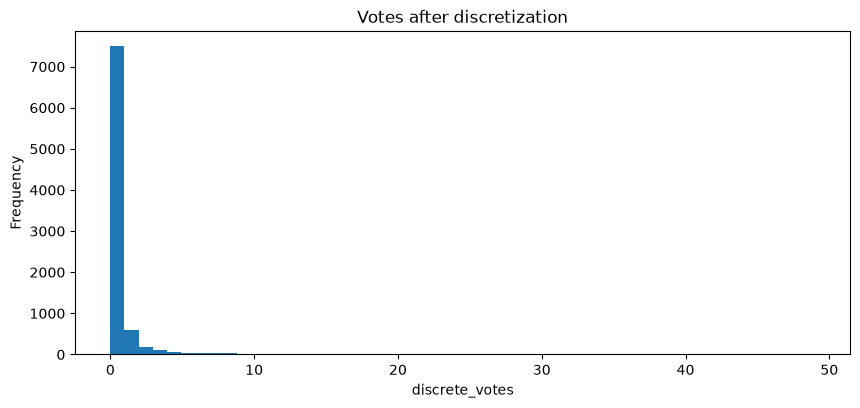

In [33]:
X_votes.discrete_votes.plot.hist(bins=50, figsize=(10,4.2));
plt.xlabel('discrete_votes');
plt.title('Votes after discretization');

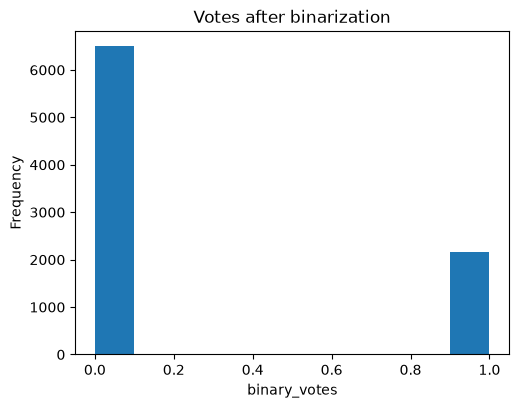

In [34]:
X_votes.binary_votes.plot.hist();
plt.xlabel('binary_votes');
plt.title('Votes after binarization');

### Exercise 4: Scale the `Votes` field

In the Learning Notebook, you also learned that numerical data can be scaled. 

In the function below, implement the scaling of the field `Votes` in three different ways:
* create a new field called `minmaxscaled_votes` which scales the `Votes` field to the range \[0,1\];
* create a new field called `standardscaled_votes` which scales the `Votes` field such that the *mean* is 0 and the standard deviation is 1;
* create a new field called `robustscaled_votes` which scales the `Votes` field such that the *median* is 0 and it is scaled according to the Interquartile Range.

In [35]:
def scale_votes(X):
    """
    Scales the Votes field from the provided dataframe in three different ways,
    creating three new columns:
    minmaxscaled_votes: scaled to range [0,1]
    standardscaled_votes: scaled to mean 0 and stdev 1
    robustscaled_votes: scaled to median 0 and according to the IQR

    Args:
        X (pd.DataFrame): dataframe with the data to be scaled
    Returns:
        X_s (pd.DataFrame): dataframe with the new scaled columns
    """
    X_s = X.copy()
    
    # YOUR CODE HERE
    X_s["minmaxscaled_votes"] = MinMaxScaler().fit_transform(X_s[["Votes"]].to_numpy(dtype=float, copy=True))
    X_s["standardscaled_votes"] = StandardScaler().fit_transform(X_s[["Votes"]].to_numpy(dtype=float, copy=True))
    X_s["robustscaled_votes"] = RobustScaler().fit_transform(X_s[["Votes"]].to_numpy(dtype=float, copy=True))

    return X_s

In [36]:
data = pd.read_csv('data/zomato.csv').convert_dtypes()
X_scaled = scale_votes(data)
assert isinstance(X_scaled,pd.DataFrame), 'The output should be a pandas dataframe.'
assert X_scaled.shape == (data.shape[0],data.shape[1]+3), 'The shape of the resulting dataframe is not correct.'
assert 'minmaxscaled_votes' in X_scaled.columns, 'The minmaxscaled_votes column is missing.'
assert 'standardscaled_votes' in X_scaled.columns, 'The standardscaled_votes column is missing.'
assert 'robustscaled_votes' in X_scaled.columns, 'The robustscaled_votes column is missing.'
assert X_scaled.minmaxscaled_votes.dtype==float, 'The data type of the minmaxscaled_votes column is not correct.'
assert X_scaled.standardscaled_votes.dtype==float, 'The data type of the standardscaled_votes column is not correct.'
assert X_scaled.robustscaled_votes.dtype==float, 'The data type of the robustscaled_votes column is not correct.'
assert X_scaled.minmaxscaled_votes.min() == 0 , 'The minmaxscaled_votes column is not scaled properly.'
assert X_scaled.minmaxscaled_votes.max() == 1, 'The minmaxscaled_votes column is not scaled properly.'
np.testing.assert_almost_equal(X_scaled.minmaxscaled_votes.sum(), 108.57536125845985, decimal=3, 
                               err_msg='The minmaxscaled_votes column is not scaled properly.')
np.testing.assert_almost_equal(X_scaled.standardscaled_votes.mean(), 0.0, 
                               err_msg='The standardscaled_votes column is not scaled properly.')
np.testing.assert_almost_equal(X_scaled.standardscaled_votes.var(), 1.0, decimal=3, 
                               err_msg='The standardscaled_votes column is not scaled properly.')
np.testing.assert_almost_equal(X_scaled.robustscaled_votes.median(), 0.0,
                               err_msg='The robustscaled_votes column is not scaled properly.')
np.testing.assert_almost_equal(X_scaled.robustscaled_votes.var(), 19.880, decimal=3,
                               err_msg='The robustscaled_votes column is not scaled properly.')
np.testing.assert_almost_equal(X_scaled.robustscaled_votes.sum(), 10203.281, decimal=3,
                               err_msg='The robustscaled_votes column is not scaled properly.')

Plot the distributions for the new fields you just calculated. We're using the log scale so that you can better see the less frequent bins.

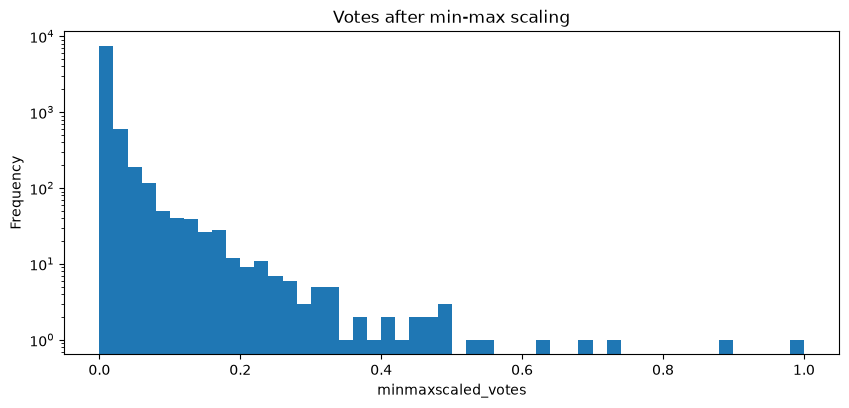

In [37]:
X_scaled.minmaxscaled_votes.plot.hist(bins=50, figsize=(10,4.2), log=True);
plt.xlabel('minmaxscaled_votes');
plt.title('Votes after min-max scaling');

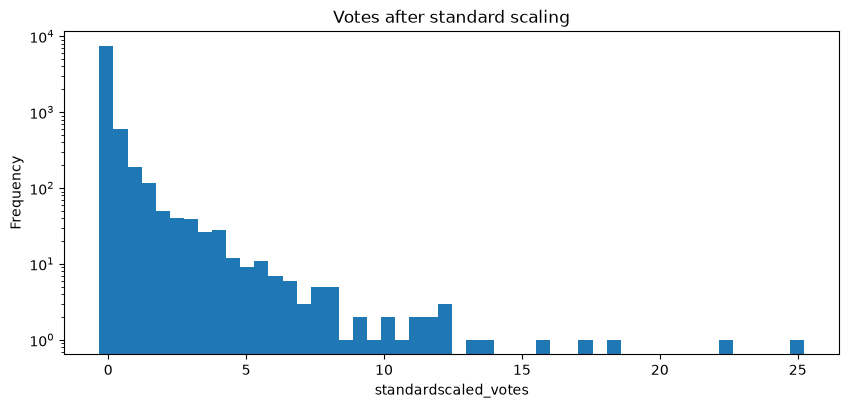

In [38]:
X_scaled.standardscaled_votes.plot.hist(bins=50, figsize=(10,4.2), log=True);
plt.xlabel('standardscaled_votes');
plt.title('Votes after standard scaling');

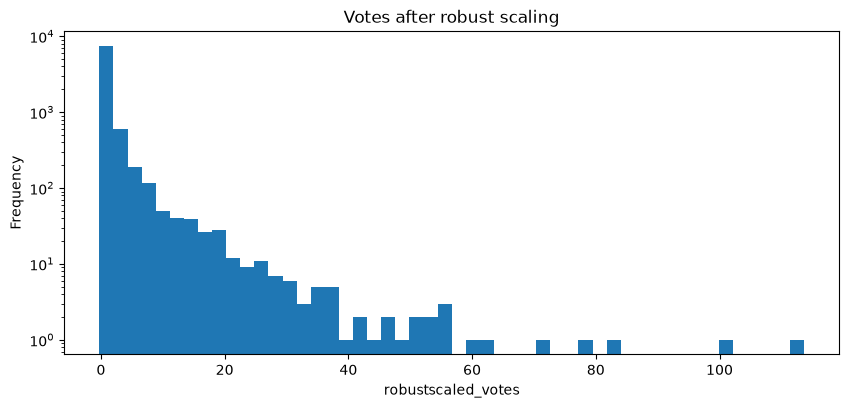

In [39]:
X_scaled.robustscaled_votes.plot.hist(bins=50, figsize=(10,4.2), log=True);
plt.xlabel('robustscaled_votes');
plt.title('Votes after robust scaling');

Compare to the original Votes distribution:

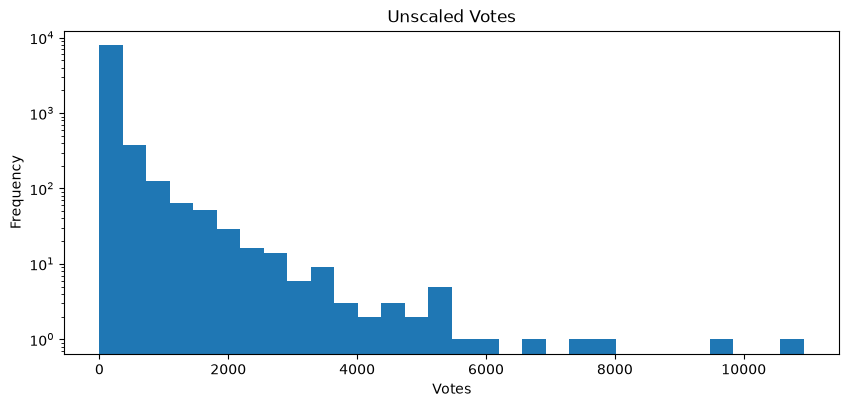

In [40]:
X_scaled.Votes.plot.hist(bins=30, figsize=(10,4.2), log=True);
plt.xlabel('Votes');
plt.title('Unscaled Votes');

### Exercise 5: Ordinal encode the `Rating text` feature

Finally, let's deal with the categorical features.

In the function below, create a new field called `rating_text_encoded` which is the result of ordinal encoding of the `Rating text` feature.

In [41]:
def encode_rating_text(X):
    """
    Ordinal encodes the 'Rating text' column of the provided dataframe,
    creating a new column rating_text_encoded

    Args:
        X (pd.DataFrame): dataframe with the data to be encoded
    Returns:
        X_r (pd.DataFrame): dataframe with the new encoded column
    """
    X_r = X.copy()
    X_r["rating_text_encoded"] = ce.OrdinalEncoder(cols=['Rating text']).fit_transform(X_r[['Rating text']])['Rating text']
    
    return X_r

In [42]:
data = pd.read_csv('data/zomato.csv').convert_dtypes()
X_rating_text = encode_rating_text(data)
assert isinstance(X_rating_text,pd.DataFrame), 'The output should be a pandas dataframe.'
assert X_rating_text.shape == (data.shape[0],data.shape[1]+1), 'The shape of the resulting dataframe is not correct.'
assert 'rating_text_encoded' in X_rating_text.columns, 'The rating_text_encoded column is missing.'
assert hashlib.sha256(json.dumps(''.join(X_rating_text.rating_text_encoded.astype(str))).encode()).hexdigest() == \
'5d490edf92c8fdc35e465f10e2cd80b1dcb912377503e04ba8f90fb4d9733fbd', 'The rating_text_encoded column is not encoded correctly.'

### Exercise 6: One-hot encode the `Cuisines` feature

Finally, implement a one-hot encoding of the `Cuisines` feature in the function below. Pay attention to the following points:
* return the original DataFrame `X` with the `Cuisines` feature replaced by the new ones resulting from the one-hot encoding;
* the new features should be named as `Cuisines_category`, where `category` takes up the values of the categories of the `Cuisines` feature.
* there should be an extra category for unknown features

In [ ]:
def encode_cuisines(X):
    """
    One-hot encodes the Cuisines column of the provided dataframe.
    """
    X_t = X.copy()

    # Replace missing values with the "unknown" category
    X_t['Cuisines'] = X_t['Cuisines'].fillna('-1')

    # One-hot encode
    cuisines_dummies = pd.get_dummies(
        X_t['Cuisines'],
        prefix='Cuisines',
        dtype=int
    )

    if 'Cuisines_-1' not in cuisines_dummies.columns:
        cuisines_dummies['Cuisines_-1'] = 0

    # Replace original Cuisines column
    X_t = X_t.drop(columns=['Cuisines'])
    X_t = pd.concat([X_t, cuisines_dummies], axis=1)

    return X_t

In [44]:
data = pd.read_csv('data/zomato.csv').convert_dtypes()
X_cuisines = encode_cuisines(data)
assert isinstance(X_cuisines,pd.DataFrame), 'The output should be a pandas dataframe.'
assert X_cuisines.shape == (data.shape[0],data.shape[1]+len(data.Cuisines.unique())), \
'The shape of the resulting dataframe is not correct.'
assert sum([j in X_cuisines.columns for j in ['Cuisines_'+i for i in data.Cuisines.unique()]])==len(data.Cuisines.unique()), \
'Some of the expected new columns are missing.'
assert 'Cuisines_-1' in X_cuisines.columns, 'The feature for unseen categories is missing.'
assert X_cuisines[[i for i in X_cuisines.columns if i.startswith('Cuisines_')]].max(axis=None)==1, \
'The newly created columns are not encoded correctly.'
assert X_cuisines[[i for i in X_cuisines.columns if i.startswith('Cuisines_')]].min(axis=None)==0, \
'The newly created columns are not encoded correctly.'
assert X_cuisines[[i for i in X_cuisines.columns if i.startswith('Cuisines_')]].sum().sum()==8652, \
'The newly created columns are not encoded correctly.'

Congratulations! You made it to the end of another exercise notebook. You win a Tesseract.

<img src='media/8-cell-simple.gif' title='By JasonHise at English Wikipedia - Transferred from en.wikipedia to Commons., Public Domain, https://commons.wikimedia.org/w/index.php?curid=1724044'>